# 第 04 步：我绘制净值与回撤，定位一次最深下跌

<!-- SNAPSHOT_NOTE -->
## 我的数据准备说明

我在本页记录的是完整快照上的实际运行。如果我从 GitHub 克隆源码，我先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。


## 我的目标与运行范围

我在上一节得到期末累计收益，但这个终点数字无法说明持有过程中的损失体验。本步我继续观察 `SYN001` 的同一条人工价格路径，计算截至每日的历史高点、每日回撤和最大回撤，并把对应的峰值与谷值放回时间轴。

我的前提仍是首日收盘净值设为 1、单股持续持有、没有外部现金流和交易费用。这里不是多因子策略回测，也没有按照图上的峰谷提前买卖。我用事后图表描述已经发生的路径，不能把事后才知道的最低点当成当时可用的交易信号。

我已完成 [第 03 步](../03_cumulative_returns/README.md)，并安装 `.[plots]`。我在仓库根目录执行：

```powershell
.\.venv\Scripts\python.exe examples/04_nav_drawdown.py
```

脚本读取固定人工输入，保存图到 `runs/first_demo_20261107/figures/SYN001_nav_drawdown.png`。本节引用的是该现成图，不使用其他股票或另造一条曲线。

## 我固定回撤公式与符号

我设 `N_t` 为第 t 日净值，截至当日的历史最高净值为：

$$
H_t=\max_{0\le s\le t}N_s.
$$

每日带符号回撤为：

$$
D_t=\frac{N_t}{H_t}-1\le0.
$$

我把最大回撤的带符号值写成 `min(D_t)`，把便于展示的最大回撤幅度写成 `-min(D_t)`。前者是负数或零，后者是正数或零。若一条净值从 1.2 跌到 0.9，回撤为 `0.9/1.2-1=-25%`，不是相对最初资金的 -10%。这是说明公式的算术例子，不是当前样本的峰谷数值。

我不能用 `nav.max()` 对全历史只求一个最高点，再给每一天都除以它。那会把尚未出现的未来高点放进早期日期，使早期回撤失去“截至当时”的定义。我也不能把最低净值除以最高净值直接当最大回撤，因为全局最低点可能发生在全局最高点之前。

## 我逐行解释核心代码

```python
stock["running_peak"] = stock["nav"].cummax(skipna=False)
stock["drawdown"] = stock["nav"] / stock["running_peak"] - 1
max_drawdown_signed = stock["drawdown"].min()
max_drawdown = -max_drawdown_signed
```

`cummax` 在每一行只使用当前及此前的净值，得到一条不会下降的高水位线。`skipna=False` 表达我不想在中途缺失后继续假装路径完整；本脚本已先要求价格完整且为正。第二行将当前净值与同一日期的高水位比较。第三行找最负的回撤；第四行转换为正幅度，便于图标题和文字展示。

我没有把 `max_drawdown` 直接命名为收益率，因为它衡量的是从前高下跌的幅度，不是起点到终点的回报。后续核心绩效表里的 `max_drawdown` 使用负数口径，因此跨文件比较时我需要先看字段说明，不能只看同名字段便假定符号一致。

```python
trough_index = stock["drawdown"].idxmin()
peak_index = stock.loc[:trough_index, "nav"].idxmax()
peak = stock.loc[peak_index]
trough = stock.loc[trough_index]
```

`idxmin()` 返回最深回撤所在的行标签，而不是回撤数值。此前重排过索引，因此当前标签与行顺序一致。第二行先截取谷底及之前的区间，再寻找其中最高净值，确保峰值在谷底之前。`.loc[:trough_index]` 包含端点。若最深回撤或高点有并列，当前 pandas 选择第一次出现的位置；我对日期解释也沿用这一确定规则。

## 我的实际数值与时间顺序

| 我核对的指标 | 当前人工样本结果 |
| --- | ---: |
| 起点日期 | 2019-01-01 |
| 期末日期 | 2025-12-31 |
| 期末净值 | 0.3465317571 |
| 期末累计收益 | -65.346824% |
| 最大回撤带符号值 | -0.7572110610 |
| 最大回撤幅度 | 75.721106% |
| 对应前高日期 | 2019-08-08 |
| 对应前高净值 | 1.1557040013 |
| 对应谷底日期 | 2025-11-20 |
| 对应谷底净值 | 0.2805921483 |

我直接复算 `0.2805921483/1.1557040013-1≈-0.7572110610`。期末累计亏损约 65.35%，而最大回撤约 75.72%，两者不相等，原因是参照点不同：前者相对首日净值 1，后者相对之前达到的高点。

当前期末回撤约为 **-70.01552675%**，也不是最深回撤。谷底之后出现了一定恢复，但期末仍明显低于过去高点。我因此分别保存“期末表现”和“历史最差路径”，没有用后来的反弹抹去先前的下跌。

我还核对开头几个日期：首日 `NAV=1`、历史高点 1、回撤 0；2019-01-02 净值约 0.9706366333，回撤约 -2.936337%；2019-01-03 净值约 1.0031889131，创新高，所以回撤回到 0。2019-01-07 的净值虽然仍接近起点，但低于 01-04 的前高，回撤约 -1.584982%。这些小例子帮助我确认 `cummax` 和除法方向正确。

## 我怎样阅读现成图表

![我保存的 SYN001 人工净值与回撤](../../runs/first_demo_20261107/figures/SYN001_nav_drawdown.png)

上图的实线是净值，虚线是截至当日的历史高点，下图是带负号的回撤。我的两个子图共用日期轴，所以可以把上方某段净值下跌与下方回撤加深对应起来。水平参考线 1 代表起点财富，不代表每次重新建仓；下方的 0 代表处于历史高点，而不是价格没有波动。

图上标注峰值和谷值是为定位本次最大回撤，不是投资建议。我计算的是日收盘估值路径的回撤，没有使用日内最高价和最低价，因此不能声称覆盖持有期间每一个盘中极端价格。

## 我解释绘图代码的关键选择

```python
matplotlib.use("Agg")
fig, (ax_nav, ax_dd) = plt.subplots(2, 1, sharex=True)
ax_dd.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
fig.savefig(output_path, dpi=180)
plt.close(fig)
```

`Agg` 让脚本直接生成图片，不依赖交互窗口；它需要在导入 `pyplot` 前设置。`subplots` 创建上下两个坐标轴，`sharex=True` 保持时间轴一致。`PercentFormatter(xmax=1.0)` 告诉图表把原始小数 1 显示为 100%，因此我不用提前把回撤乘 100。`savefig` 把画布保存到确定路径，`close` 在保存后释放画布。

脚本还设置中文字体候选；不同系统是否安装这些字体，会影响中文显示。我把字体缺失与金融计算错误分开排查。图片能够生成不代表所有数字就正确，图像标注仍需要与表格核对。

## 我进一步说明路径风险的解释范围

我把最大回撤看作一个路径指标。只知道起点和终点，通常不能还原中间的高水位与下跌过程；即使两份资产的累计收益相同，中间经历的波动和回撤也可能不同。最大回撤又只保留最深的一次幅度，不会完整表达每次下跌的次数、持续时间、恢复速度或收益分布，所以我不会把一个数字称为“全部风险”。

当前记录给出了前高和谷底，但我没有把两者之间的自然日期差直接解释成回撤已经恢复所需时间。恢复需要净值重新达到原来的高水位；谷底只是最深位置，不是恢复终点。当前期末净值仍低于该高点，所以我也不会把期末之前的反弹说成已经恢复。

我用一个单独的算术例子理解损失与修复的非对称性：财富从一百降到五十，是损失一半；再从五十回到一百，需要在剩余基础上翻倍，而不是上涨一半。这个例子解释了为什么回撤幅度必须明确分母。我没有据此预测当前人工股票何时恢复，也没有把最大历史损失当作未来最差损失的上限。

我的净值基准还应被纳入风险计算。若我从首个亏损之后才开始取历史高点，可能漏掉一开始相对初始资金的下跌。本节首日净值就是一，并进入 `cummax`；后续真实账户的首次交易成本会使第一笔净值低于初始基准，那时也需要保留初始基准参加回撤核对。我的检查因此不仅关心公式写法，还关心从哪一天、哪一个资金基数开始使用公式。

## 我记录的错误与验收

| 我的错误做法 | 我为什么排除它 |
| --- | --- |
| 我用最差单日收益充当最大回撤 | 单日冲击与多日累计从高点下跌是不同指标 |
| 我用全历史最高净值衡量每个早期日期 | 引入未来高点，违背截至当日定义 |
| 我忽略峰谷先后顺序 | 可能拼出时间上无法发生的下跌 |
| 我同时给百分数数据再套百分比格式 | 图上显示会放大 100 倍 |
| 我把最大回撤负号当作计算错误 | 当前程序分别保存带符号值和正幅度 |
| 我看到反弹便认为风险已经消失 | 历史最深回撤仍是已经发生的路径事实 |

我的验收是公式、前几行、峰谷日期和图表四者一致；图中的 75.72% 不是凭视觉估计，而是从保存的净值路径算出。本步结论仍限于人工单股持有序列。下一步我进入 [第 05 步](../05_momentum_factor/README.md)，把累计收益的思路改造成每个时点仅回看历史的滚动因子。

## 我的完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。我先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/04_nav_drawdown.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
"""第四课：绘制单只模拟股票的净值与回撤，计算最大回撤。"""

from pathlib import Path
import pandas as pd
import matplotlib

# 直接保存图片，脚本可以在终端运行。
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

# 沿用前几课：读取、筛选、按独立的模拟交易日历对齐。
project_dir = Path(__file__).resolve().parents[1]
data_path = project_dir / "runs" / "first_demo_20261107" / "input" / "prices.csv"
prices = pd.read_csv(data_path, dtype={"symbol": "string"}, parse_dates=["date"])
symbol = "SYN001"
stock = prices.loc[prices["symbol"] == symbol].copy()
stock = stock.sort_values("date").reset_index(drop=True)
calendar = pd.read_csv(data_path.with_name("calendar.csv"), parse_dates=["date"])
stock = stock.set_index("date").reindex(calendar["date"]).reset_index()

### 完整实现 · 单元 2

In [3]:
if stock.empty or stock["adj_close"].isna().any() or (stock["adj_close"] <= 0).any():
    raise ValueError("本课需要完整且为正的复权收盘价，请先检查股票代码和缺失行情。")

### 完整实现 · 单元 3

In [4]:
# 1. 本课仍以首日收盘为起点，持续持有这只股票，不计费用。
stock["daily_return"] = stock["adj_close"] / stock["adj_close"].shift(1) - 1
growth_factor = 1 + stock["daily_return"]
growth_factor.iloc[0] = 1.0
stock["nav"] = growth_factor.cumprod(skipna=False)
stock["cumulative_return"] = stock["nav"] - 1

# 2. 截至每一天的历史最高净值；只能用该日及之前的数据。
stock["running_peak"] = stock["nav"].cummax(skipna=False)

# 3. 每日回撤是负数或零；最大回撤幅度以正数展示。
stock["drawdown"] = stock["nav"] / stock["running_peak"] - 1
max_drawdown_signed = stock["drawdown"].min()
max_drawdown = -max_drawdown_signed

# 4. 找到最深回撤的谷底，以及发生在它之前的峰值。
trough_index = stock["drawdown"].idxmin()
peak_index = stock.loc[:trough_index, "nav"].idxmax()
peak = stock.loc[peak_index]
trough = stock.loc[trough_index]
final_return = stock["cumulative_return"].iloc[-1]

# 5. 两幅图共用日期轴，上方净值、下方回撤。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11
fig, (ax_nav, ax_dd) = plt.subplots(
    2, 1, figsize=(11, 7.2), sharex=True,
    gridspec_kw={"height_ratios": [2, 1]}, layout="constrained",
)
fig.suptitle(f"{symbol}：净值曲线与回撤（模拟数据）", fontsize=17)
ax_nav.set_title(
    f"期末累计收益率 {final_return:.2%}    最大回撤幅度 {max_drawdown:.2%}",
    loc="left", fontsize=11, pad=10,
)

# 6. 净值实线与截至当日的历史高点虚线。
ax_nav.plot(stock["date"], stock["nav"], color="#3268A8", linewidth=1.6, label="净值 NAV")
ax_nav.plot(stock["date"], stock["running_peak"], color="#747D86", linewidth=1.2,
            linestyle="--", label="截至当日的历史高点")
ax_nav.axhline(1.0, color="#9FA6AD", linewidth=0.8, linestyle=":")
ax_nav.set_ylabel("净值（首日 = 1）")
ax_nav.set_ylim(0, max(1.25, stock["nav"].max() * 1.16))
ax_nav.legend(loc="upper right", frameon=False, fontsize=10)

# 峰值和谷值标记，仅用于定位本次最大回撤。
ax_nav.scatter(peak["date"], peak["nav"], color="#3268A8", marker="o", s=40, zorder=5)
ax_nav.scatter(trough["date"], trough["nav"], color="#B46A31", marker="v", s=50, zorder=5)
ax_nav.annotate(
    f"前高 {peak['date']:%Y-%m-%d}\n净值 {peak['nav']:.4f}",
    xy=(peak["date"], peak["nav"]), xytext=(22, 20), textcoords="offset points",
    fontsize=10, arrowprops={"arrowstyle": "->", "color": "#747D86"},
)

Text(22, 20, '前高 2019-08-08\n净值 1.1557')

### 完整实现 · 单元 4

In [5]:
ax_nav.annotate(
    f"谷底 {trough['date']:%Y-%m-%d}\n净值 {trough['nav']:.4f}",
    xy=(trough["date"], trough["nav"]), xytext=(-175, -35), textcoords="offset points",
    fontsize=10, arrowprops={"arrowstyle": "->", "color": "#747D86"},
)

# 7. 回撤以小数计算，坐标轴再格式化为百分比。
ax_dd.plot(stock["date"], stock["drawdown"], color="#3268A8", linewidth=1.1)
ax_dd.fill_between(stock["date"], stock["drawdown"], 0, color="#3268A8", alpha=0.18)
ax_dd.axhline(0, color="#747D86", linewidth=0.8)
ax_dd.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
ax_dd.set_ylabel("相对历史高点的回撤")
ax_dd.set_ylim(min(-0.05, max_drawdown_signed * 1.12), 0.04)
ax_dd.scatter(trough["date"], trough["drawdown"], color="#B46A31", marker="v", s=45, zorder=5)
ax_dd.annotate(
    f"最大回撤幅度 {max_drawdown:.2%}",
    xy=(trough["date"], trough["drawdown"]), xytext=(-190, 70), textcoords="offset points",
    fontsize=10, arrowprops={"arrowstyle": "->", "color": "#747D86"},
)

# 稀疏日期刻度，并保留起点和终点。
date_ticks = pd.date_range(stock["date"].iloc[0], stock["date"].iloc[-1], freq="2YS")
date_ticks = date_ticks.union(pd.DatetimeIndex([stock["date"].iloc[0], stock["date"].iloc[-1]]))
ax_dd.set_xticks(date_ticks)
ax_dd.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax_dd.set_xlim(stock["date"].iloc[0], stock["date"].iloc[-1])
ax_dd.set_xlabel("日期（模拟工作日日历，单只股票持续持有，不计费用）")
for ax in (ax_nav, ax_dd):
    ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#B5BDC5")
    ax.tick_params(axis="both", labelsize=10)

# 8. 保存图片；关闭画布以释放内存，不修改原始行情。
output_dir = data_path.parent.parent / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{symbol}_nav_drawdown.png"
fig.savefig(output_path, dpi=180)
plt.close(fig)

print("模拟股票：", symbol)
print(f"期末累计收益率：{final_return:.6%}")
print(f"最大回撤幅度（正数）：{max_drawdown:.6%}")
print(f"最深回撤（带负号）：{max_drawdown_signed:.6%}")
print(f"峰值日期：{peak['date']:%Y-%m-%d}，净值：{peak['nav']:.6f}")

模拟股票： SYN001
期末累计收益率：-65.346824%
最大回撤幅度（正数）：75.721106%
最深回撤（带负号）：-75.721106%
峰值日期：2019-08-08，净值：1.155704


### 完整实现 · 单元 5

In [6]:
print(f"谷值日期：{trough['date']:%Y-%m-%d}，净值：{trough['nav']:.6f}")
print("\n前 6 行：")
print(stock[["date", "nav", "running_peak", "drawdown"]].head(6).to_string(index=False))
print("\n图已保存：", output_path)

谷值日期：2025-11-20，净值：0.280592

前 6 行：
      date      nav  running_peak  drawdown
2019-01-01 1.000000      1.000000  0.000000
2019-01-02 0.970637      1.000000 -0.029363
2019-01-03 1.003189      1.003189  0.000000
2019-01-04 1.005633      1.005633  0.000000
2019-01-07 0.989694      1.005633 -0.015850
2019-01-08 1.006397      1.006397  0.000000

图已保存： .\runs\first_demo_20261107\figures\SYN001_nav_drawdown.png


## 我的图表输出

完整脚本已经保存图表。我在这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

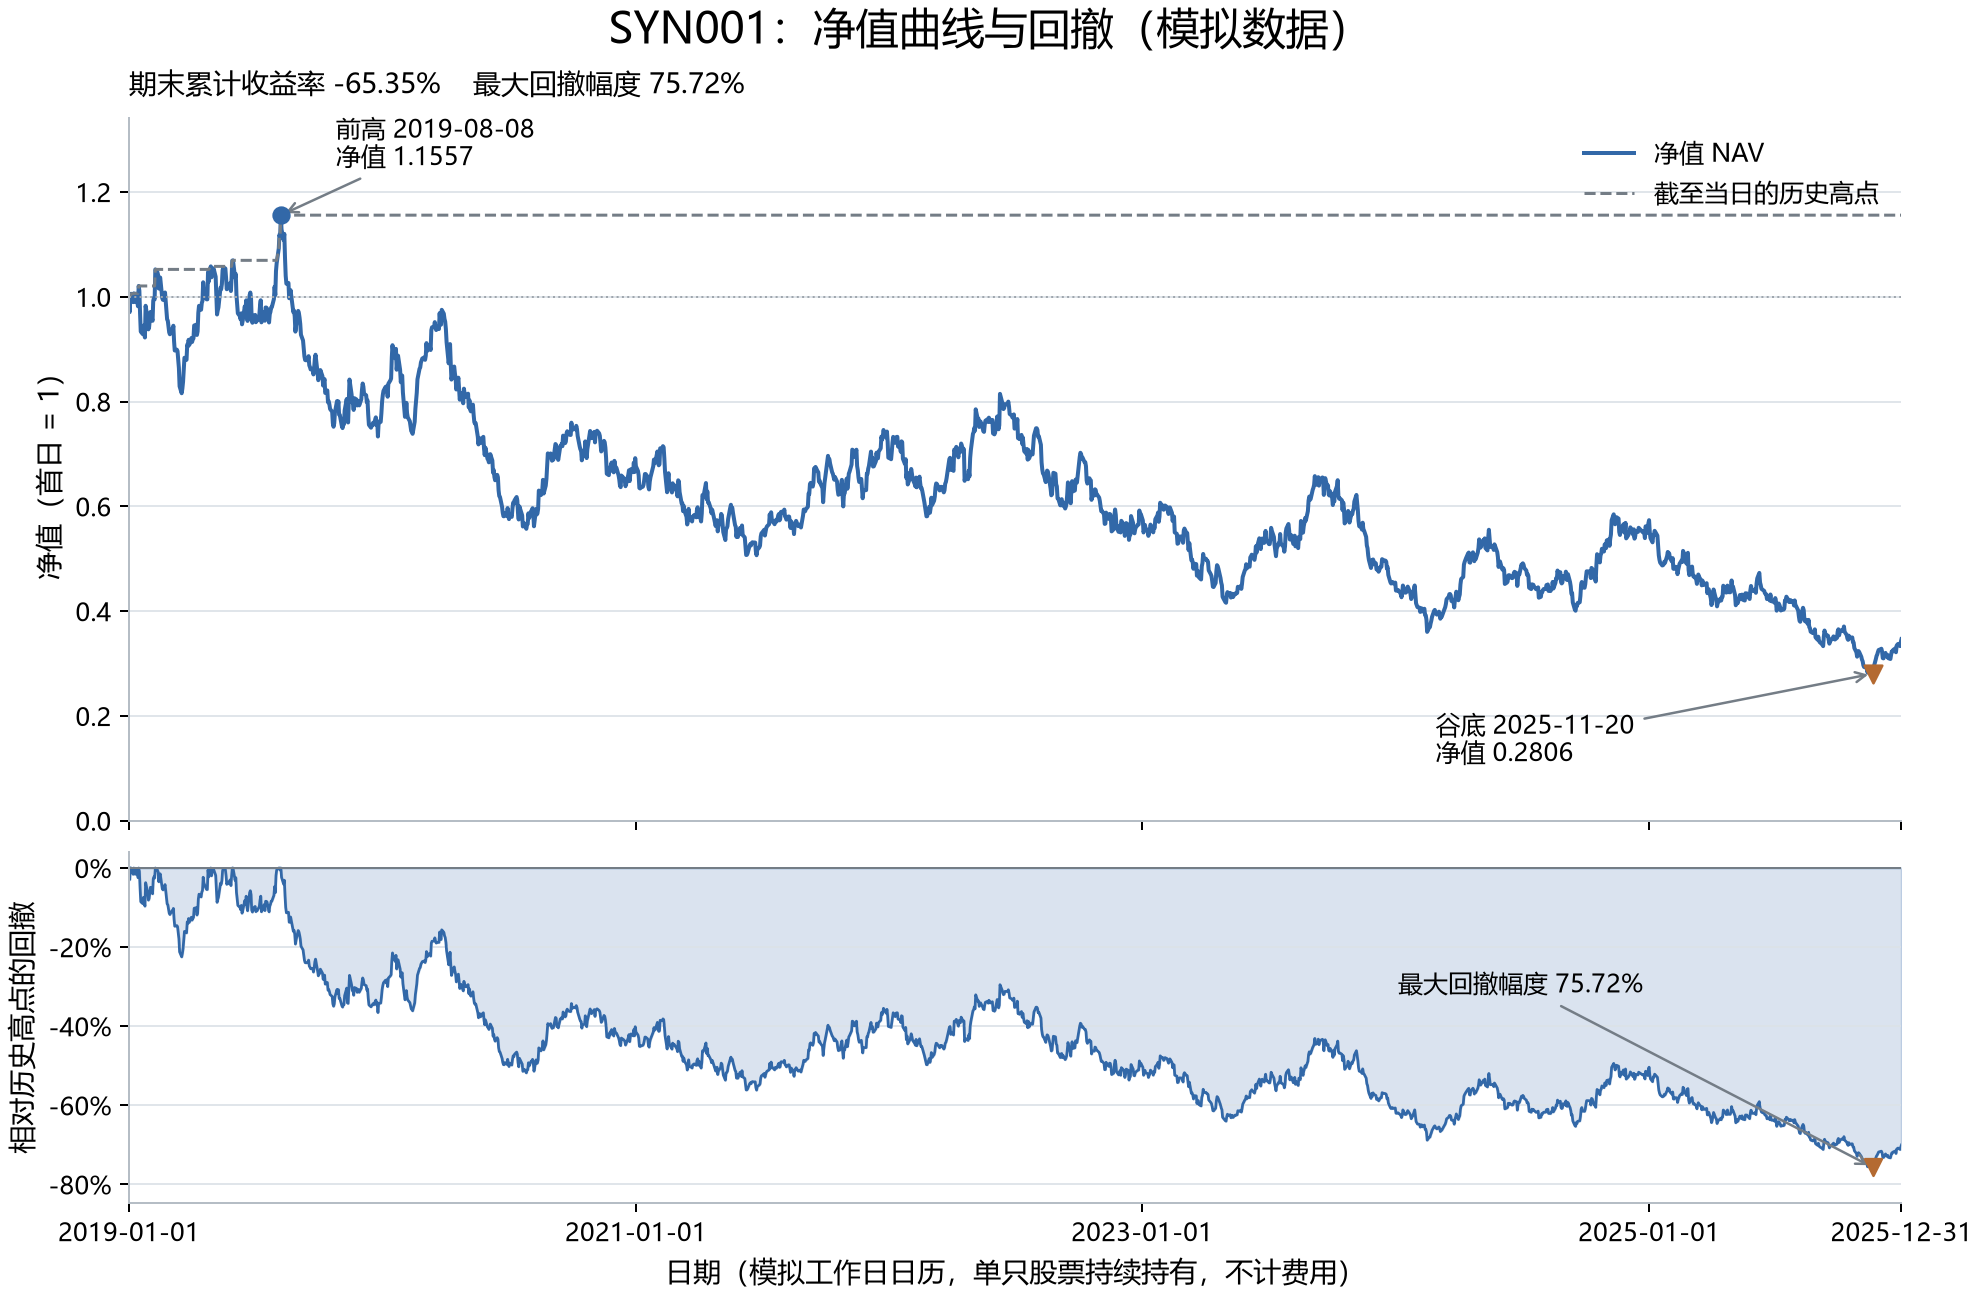

In [7]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/figures/SYN001_nav_drawdown.png')))

## 我的复核

我在干净内核中按顺序执行以上实现；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。